# 01: Exploratory data analysis

**Robot.** A Universal Robots UR3 is a small six-joint collaborative robot arm (3 kg payload, 500 mm reach). The six joints, from base to tool, are base, shoulder, elbow and wrists 1–3. The dataset calls them J0–J5. When the controller sees that the arm can't follow its planned path (a collision, an overload, a limit violation), it raises a **protective stop**: the arm halts until someone resumes it. The full primer with sources is in [`docs/ur3.md`](../docs/ur3.md).

**Data.** [UR3 CobotOps](https://archive.ics.uci.edu/dataset/963/ur3+cobotops) (Tyrovolas et al., CC BY 4.0). It holds joint currents, temperatures and speeds, gripper current, cycle count and two fault flags, sampled at about 1 Hz.

**Questions for this notebook**
1. What state is the raw file in, and what does cleaning have to fix?
2. How are the data organised in time (sessions, sampling rate)?
3. How rare are the two faults, and how long do they last?
4. Is there a signal *before* a fault, i.e. is prediction even possible?
5. Do the sensors behave the way the physics says they should?

Each answer feeds a modelling decision in milestone 2. The reusable code lives in `src/cobot/`; this notebook only explores.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from cobot.config import PROJECT_ROOT, load_config
from cobot.data import CURRENTS, SENSORS, SPEEDS, TARGETS, TEMPERATURES, load_dataset
from cobot.labels import event_onsets
from cobot.plotting import GRIP_LOST, SERIES, STOP, apply_style, save

apply_style()
pd.set_option("display.precision", 3)
cfg = load_config().data
FIGURES = PROJECT_ROOT / "docs" / "img"
JOINT_NAMES = ["J0 base", "J1 shoulder", "J2 elbow", "J3 wrist 1", "J4 wrist 2", "J5 wrist 3"]

## 1. The raw file

Before any cleaning, let's take an inventory of everything that is wrong with the spreadsheet as downloaded.

In [2]:
raw = pd.read_excel(cfg.raw_path)
raw_sensors = raw.columns[2:21]  # Current_J0 ... Tool_current
speeds = raw.filter(like="Speed")
empty = raw[raw_sensors].isna().all(axis=1)

pd.Series(
    {
        "rows x columns": f"{raw.shape[0]} x {raw.shape[1]}",
        "column names with stray whitespace": [c for c in raw.columns if c != c.strip()],
        "joint-0 temperature column": [c for c in raw.columns if c.endswith("T0")],
        "timestamps wrapped in literal quotes": int(raw["Timestamp"].str.startswith('"').sum()),
        "rows with every sensor missing": int(empty.sum()),
        "rows with some sensors missing": int((raw[raw_sensors].isna().any(axis=1) & ~empty).sum()),
        "speed values that are float noise (0 < |v| < 1e-12)": int(
            speeds.abs().gt(0).mul(speeds.abs().lt(1e-12)).sum().sum()
        ),
        "target dtypes": raw[["Robot_ProtectiveStop", "grip_lost"]].dtypes.astype(str).to_dict(),
    }
).to_frame("finding")

,finding
rows x columns,7409 x 24
column names with stray whitespace,[cycle ]
joint-0 temperature column,[Temperature_T0]
timestamps wrapped in literal quotes,863
rows with every sensor missing,46
rows with some sensors missing,8
speed values that are float noise (0 < |v| < 1e-12),1802
target dtypes,"{'Robot_ProtectiveStop': 'float64', 'grip_lost..."


Every item above is handled in [`cobot.data.clean`](../src/cobot/data.py) and covered by a unit test:

| Issue | Fix |
|---|---|
| `cycle ` with a trailing space, mixed casing | strip names and convert to snake_case |
| `Temperature_T0` | rename to `temperature_j0`, consistent with the other joints |
| Timestamps wrapped in `"` | strip the quotes, then parse as UTC datetimes |
| 46 rows with no sensor data | drop them (no information to keep) |
| 8 rows that only kept `Current_J0` | forward-fill within the session: at 1 Hz the previous sample is the best estimate |
| Speeds such as `1e-44` | set to exactly 0 (float noise where the joint is at rest) |
| Float target with NaN vs. bool target | cast both to `int` |

## 2. Clean data

In [3]:
df = load_dataset(cfg)
print(f"{len(raw)} raw rows -> {len(df)} clean rows, {df.isna().sum().sum()} missing values")

sessions = df.groupby("session_id").agg(
    start=("timestamp", "min"),
    end=("timestamp", "max"),
    rows=("timestamp", "size"),
    cycles=("cycle", "nunique"),
)
sessions["minutes"] = (sessions["end"] - sessions["start"]).dt.total_seconds().div(60).round(1)
sessions

7409 raw rows -> 7363 clean rows, 0 missing values


,start,end,rows,cycles,minutes
session_id,,,,,
0,2022-10-26 08:17:21.847+00:00,2022-10-26 09:06:19.201+00:00,2861,104,49.0
1,2022-10-26 14:19:53.326+00:00,2022-10-26 15:36:06.580+00:00,4502,137,76.2


In [4]:
dt = df.groupby("session_id")["timestamp"].diff().dt.total_seconds()
dt.describe(percentiles=[0.01, 0.5, 0.99]).to_frame("seconds between samples").T

,count,mean,std,min,1%,50%,99%,max
seconds between samples,7361.0,1.02,0.376,0.984,1.0,1.005,1.026,31.15


The recording is **two sessions** about five hours apart: 49 minutes in the morning and 76 in the afternoon. Within a session the sampling is a steady ~1 Hz; there is a single 31 s hiccup, too short to split on. Two consequences for modelling:

- Rolling-window features must be computed **per session**, so a window never spans the five-hour gap.
- Rows are a time series, not independent samples, so a random train/test split would leak the future into training.

## 3. Fault events

In [5]:
def event_summary(target: str) -> pd.Series:
    onsets = event_onsets(df[target], df["session_id"])
    runs = df[target].groupby(onsets.cumsum()).sum()[lambda s: s > 0]
    return pd.Series(
        {
            "positive rows": int(df[target].sum()),
            "share of rows (%)": round(100 * df[target].mean(), 2),
            "events (onsets)": int(onsets.sum()),
            "median event length (s)": runs.median(),
            "longest event (s)": runs.max(),
            "cycles affected": df.loc[df[target].eq(1), "cycle"].nunique(),
        }
    )


pd.DataFrame({t: event_summary(t) for t in TARGETS}).map(lambda v: f"{v:g}")

,protective_stop,grip_lost
positive rows,278,243
share of rows (%),3.78,3.3
events (onsets),108,74
median event length (s),2,2
longest event (s),12,19
cycles affected,78,51


In [6]:
pd.crosstab(df["protective_stop"], df["grip_lost"], margins=True)

grip_lost,0,1,All
protective_stop,,,
0,6845,240,7085
1,275,3,278
All,7120,243,7363


- Both faults are **rare** (3–4% of rows): classic imbalanced classification. Accuracy would be meaningless (predicting "no fault" every time scores 96%), so modelling uses PR-AUC and recall.
- Faults are **short events**: a median of 2 s, at most 12 s for stops and 19 s for grip losses. The natural unit is the *event* (108 stops, 74 grip losses), not the row.
- The two faults almost never overlap (3 rows), so they are separate phenomena and get separate models.

## 4. A day in the life of the arm

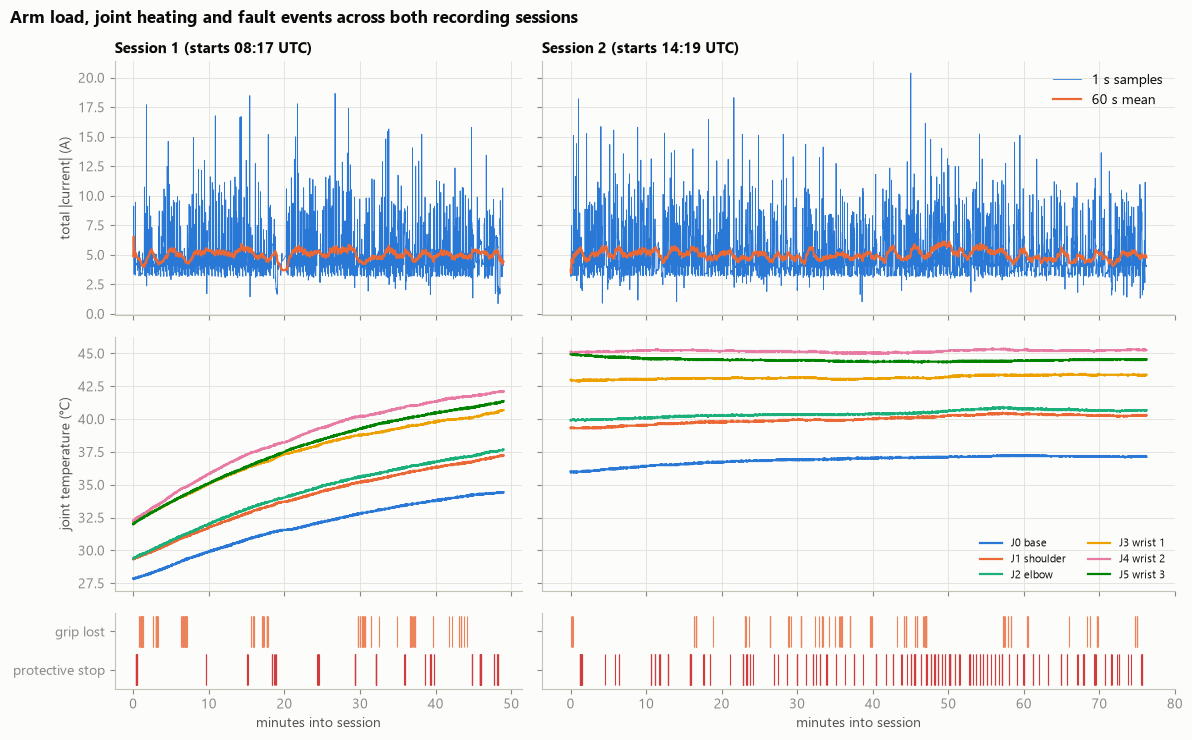

In [7]:
fig, axes = plt.subplots(
    3,
    2,
    figsize=(12, 7.5),
    sharex="col",
    sharey="row",
    gridspec_kw={"height_ratios": [2, 2, 0.6], "width_ratios": sessions["minutes"]},
)
for col, (sid, s) in enumerate(df.groupby("session_id")):
    minutes = (s["timestamp"] - s["timestamp"].iloc[0]).dt.total_seconds() / 60
    total_current = s[CURRENTS].abs().sum(axis=1)
    axes[0, col].plot(minutes, total_current, color=SERIES[0], lw=0.6)
    axes[0, col].plot(
        minutes, total_current.rolling(60, min_periods=1).mean(), color=SERIES[1], lw=1.6
    )
    for j, temp in enumerate(TEMPERATURES):
        axes[1, col].plot(minutes, s[temp], color=SERIES[j], label=JOINT_NAMES[j])
    for k, (target, colour) in enumerate([("protective_stop", STOP), ("grip_lost", GRIP_LOST)]):
        hits = minutes[s[target].eq(1)]
        axes[2, col].vlines(hits, k, k + 0.8, color=colour, lw=0.8)
    start = s["timestamp"].iloc[0].strftime("%H:%M")
    axes[0, col].set_title(f"Session {sid + 1} (starts {start} UTC)")
    axes[2, col].set_xlabel("minutes into session")

axes[0, 0].set_ylabel("total |current| (A)")
axes[0, 1].legend(["1 s samples", "60 s mean"], loc="upper right")
axes[1, 0].set_ylabel("joint temperature (°C)")
axes[1, 1].legend(ncol=2, loc="lower right", fontsize=8)
axes[2, 0].set_yticks([0.4, 1.4], ["protective stop", "grip lost"])
for ax in axes[2]:
    ax.grid(False)
fig.suptitle(
    "Arm load, joint heating and fault events across both recording sessions",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
save(fig, FIGURES / "eda_timeline.png")

- **Load is stationary.** Total current hovers around 5 A (60 s mean) in both sessions. Spikes come from accelerations in the pick-and-place cycle.
- **The morning session is a warm-up.** Every joint heats by 6–10 °C from a cold start. The afternoon session starts warm and stays near thermal equilibrium. The wrist joints run hottest, even though they carry the least holding current (see section 7).
- **Protective stops cluster in the afternoon.** So absolute temperature is confounded with time of day: a model could learn "warm ⇒ more stops" from two sessions alone. Feature engineering should use temperature *change* rather than raw level, and the test set must come from a later time than training.

## 5. Why the same-row label is not a prediction task

,% of samples with any joint moving
protective_stop,
in protective stop,49.6
normal,61.5


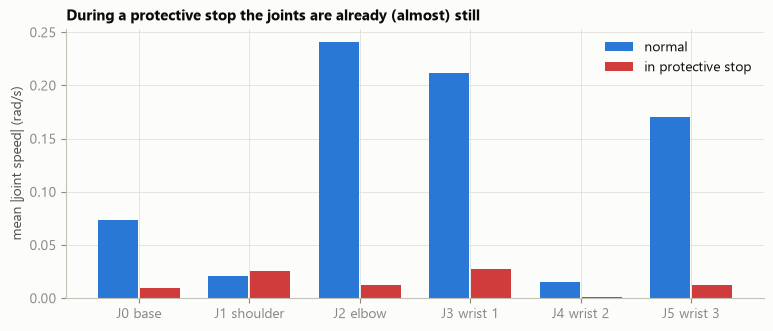

In [8]:
state = df["protective_stop"].map({0: "normal", 1: "in protective stop"})
moving = df[SPEEDS].abs().gt(1e-3).any(axis=1).groupby(state).mean().mul(100).round(1)
speed_by_state = df[SPEEDS].abs().groupby(state).mean()
speed_by_state.columns = JOINT_NAMES
display(moving.to_frame("% of samples with any joint moving"))

fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(JOINT_NAMES))
for k, (label, colour) in enumerate([("normal", SERIES[0]), ("in protective stop", STOP)]):
    ax.bar(x + (k - 0.5) * 0.38, speed_by_state.loc[label], width=0.36, color=colour, label=label)
ax.set_xticks(x, JOINT_NAMES)
ax.set_ylabel("mean |joint speed| (rad/s)")
ax.set_title("During a protective stop the joints are already (almost) still")
ax.legend()
save(fig, FIGURES / "eda_speed_during_stop.png")

When a protective stop fires, the controller brakes the arm along its path, so mean joint speed collapses by roughly an order of magnitude on every joint except the shoulder. A classifier that sees the *same row* as the label would mostly learn this reaction ("the arm is not moving") rather than the cause, and its metrics would look far better than any real early warning could.

**Decision:** frame the task as forecasting. The label at time *t* is "a protective stop **begins** within the next N seconds", and features use only samples up to *t*. Rows already inside a stop are excluded. There is nothing left to predict for them.

## 6. What happens just before a fault?

If faults arrived without warning, forecasting would be hopeless. To check, every event is aligned on its onset (t = 0). The plot shows the median and interquartile band of a few signals over the 20 s before and 5 s after.

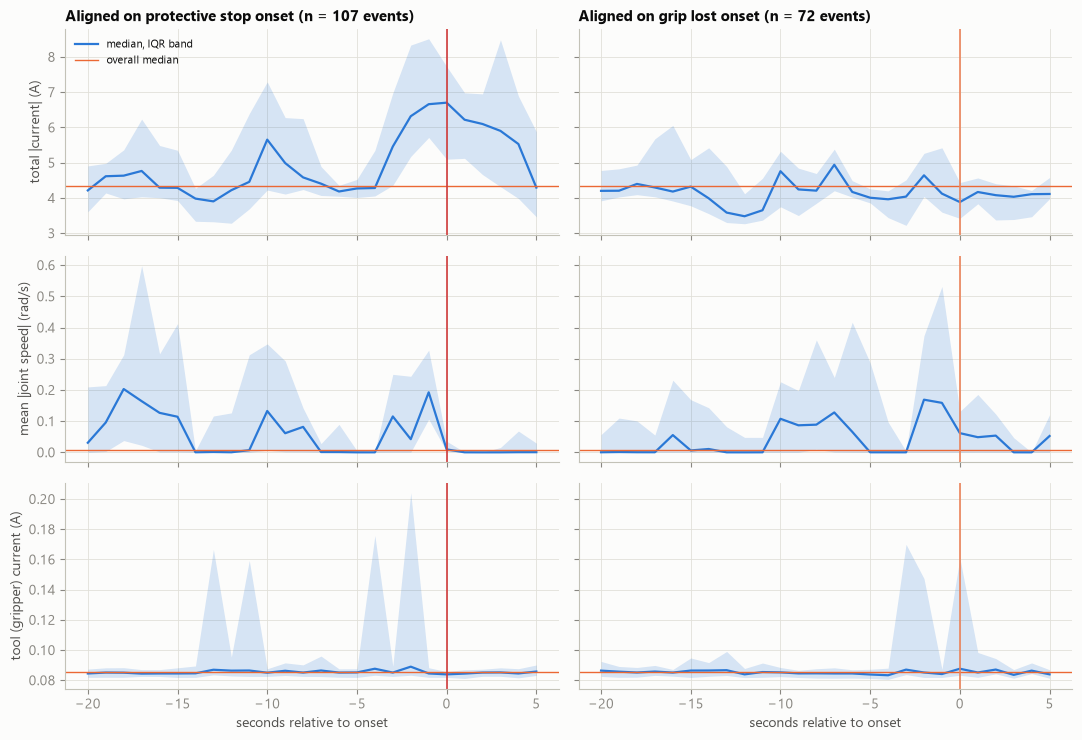

In [9]:
def aligned_windows(
    target: str, signal: pd.Series, before: int = 20, after: int = 5
) -> pd.DataFrame:
    """Stack the signal around every event onset (rows = events, columns = seconds from onset)."""
    onsets = np.flatnonzero(event_onsets(df[target], df["session_id"]))
    session = df["session_id"].to_numpy()
    windows = {
        i: signal.iloc[i - before : i + after + 1].to_numpy()
        for i in onsets
        if i - before >= 0 and i + after < len(df) and session[i - before] == session[i + after]
    }
    return pd.DataFrame(windows, index=range(-before, after + 1)).T


signals = {
    "total |current| (A)": df[CURRENTS].abs().sum(axis=1),
    "mean |joint speed| (rad/s)": df[SPEEDS].abs().mean(axis=1),
    "tool (gripper) current (A)": df["tool_current"],
}
fig, axes = plt.subplots(len(signals), 2, figsize=(11, 7.5), sharex=True, sharey="row")
for col, (target, colour, title) in enumerate(
    [("protective_stop", STOP, "protective stop"), ("grip_lost", GRIP_LOST, "grip lost")]
):
    for row, (name, signal) in enumerate(signals.items()):
        w = aligned_windows(target, signal)
        ax = axes[row, col]
        ax.fill_between(
            w.columns, w.quantile(0.25), w.quantile(0.75), color=SERIES[0], alpha=0.18, lw=0
        )
        ax.plot(w.columns, w.median(), color=SERIES[0], label="median, IQR band")
        ax.axhline(signal.median(), color=SERIES[1], lw=1, label="overall median")
        ax.axvline(0, color=colour, lw=1.2)
        if col == 0:
            ax.set_ylabel(name)
    axes[0, col].set_title(f"Aligned on {title} onset (n = {len(w)} events)")
    axes[-1, col].set_xlabel("seconds relative to onset")
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
save(fig, FIGURES / "eda_event_profiles.png")

- **Protective stops have a precursor.** Total joint current climbs from its ~4.3 A baseline to ~6.7 A over the 2–3 s before onset, with a burst of joint speed just before the arm brakes. Because motor torque scales with current (τ ≈ kₜ·I), this reads as the arm working against an unexpected load just before the controller gives up on the path. A **5 s horizon** with short rolling windows (5 s and 15 s) is therefore a sensible design, not just a guess.
- **Grip losses show no comparable precursor** in these channels; even the gripper current stays at baseline. Expect `grip_lost` to be the harder, secondary target.

## 7. Physics check: gravity load at rest

1710 samples with every joint at rest


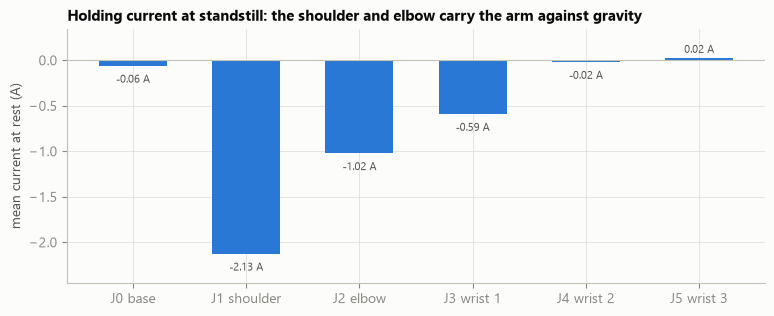

In [10]:
at_rest = df[df[SPEEDS].abs().max(axis=1).eq(0) & df["protective_stop"].eq(0)]
rest_current = at_rest[CURRENTS].mean().set_axis(JOINT_NAMES)
print(f"{len(at_rest)} samples with every joint at rest")

fig, ax = plt.subplots(figsize=(9, 3.3))
ax.bar(JOINT_NAMES, rest_current, color=SERIES[0], width=0.6)
ax.axhline(0, color="#c3c2b7", lw=0.8)
for x, v in enumerate(rest_current):
    ax.annotate(
        f"{v:.2f} A",
        (x, v),
        xytext=(0, -12 if v < 0 else 4),
        textcoords="offset points",
        ha="center",
        fontsize=8,
        color="#52514e",
    )
ax.set_ylabel("mean current at rest (A)")
ax.margins(y=0.15)
ax.set_title("Holding current at standstill: the shoulder and elbow carry the arm against gravity")
save(fig, FIGURES / "eda_holding_current.png")

With every joint stationary, the motors still have to hold the arm up. The base (J0) rotates about a vertical axis, so gravity puts no torque on it: about 0 A. The **shoulder (J1)** lifts the whole arm and draws the most holding current. The **elbow (J2)** lifts only the forearm, so it draws about half. The wrists hold almost nothing.

This is the static torque balance τ = r × m·g, read through a current sensor. It also supports the J0–J5 = base → wrist 3 mapping, which the dataset implies but never states. Practical consequence: raw current values are pose-dependent offsets. Features should look at *changes* in current (differences, rolling std), not only absolute levels.

## 8. How the signals relate

temperature channels correlate with each other at r >= 0.99


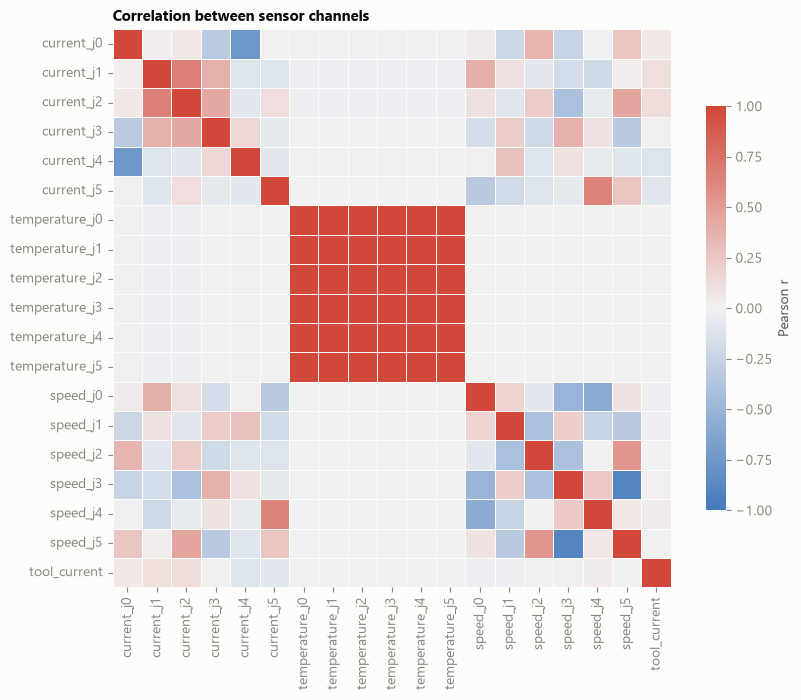

In [11]:
corr = df[SENSORS].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(
    corr,
    cmap=sns.diverging_palette(250, 15, s=75, l=50, center="light", as_cmap=True),
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    linecolor="#fcfcfb",
    cbar_kws={"shrink": 0.7, "label": "Pearson r"},
    ax=ax,
)
ax.set_title("Correlation between sensor channels")
save(fig, FIGURES / "eda_correlation.png")

temp_corr = corr.loc[TEMPERATURES, TEMPERATURES].to_numpy()[np.triu_indices(6, 1)]
print(f"temperature channels correlate with each other at r >= {temp_corr.min():.2f}")

In [12]:
by_quarter = (
    df.groupby(pd.qcut(df.index, 4, labels=["Q1", "Q2", "Q3", "Q4"]), observed=True)[TARGETS]
    .mean()
    .mul(100)
    .round(2)
)
by_quarter.index.name = "time quarter of the data"
by_quarter.rename(columns=lambda c: f"{c} rate (%)")

,protective_stop rate (%),grip_lost rate (%)
time quarter of the data,,
Q1,1.90,5.59
Q2,3.91,1.74
Q3,3.48,3.26
Q4,5.81,2.61


- The six **temperature channels are almost perfectly correlated** (r ≥ 0.99). They carry one shared signal, thermal state over time, rather than six. Keeping all six adds redundancy, not information.
- Currents and speeds correlate in pairs that reflect the motion program (e.g. wrist 1 and wrist 3 speeds move in opposition), not a fault mechanism.
- The stop rate roughly triples from the first to the last quarter of the recording (1.9% → 5.8%), which is one more reason to evaluate on the *latest* data rather than a random sample.

## Takeaways → decisions for milestone 2

| Finding | Decision |
|---|---|
| Two sessions, 1 Hz, a 5 h gap | Session id; rolling features computed per session |
| Same-row stop label mostly reflects braking | Predict a stop **onset within the next 5 s** from past data only |
| Current rises 2–3 s before stops | Rolling mean/std/max over 5 s and 15 s windows, plus first differences |
| Pose-dependent holding currents (gravity) | Favour changes over absolute levels; physics features such as total \|I\| and \|I\|·\|ω\| (power proxy) |
| Temperatures redundant and confounded with time | Use the rate of temperature change, not the raw level |
| 3–4% positives, ~100 events | PR-AUC, recall and event-level recall; class weighting; no accuracy |
| Stop rate drifts upward over time | Time-ordered split; the test set is the final stretch of the afternoon |
| No visible precursor for grip loss | Secondary target, with no strong expectations |